In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

url = "https://raw.githubusercontent.com/misbahulard/Machine-Learning/master/enjoysport.csv"
df = pd.read_csv(url)

X = df.iloc[:, :-1].values.tolist()
y = df.iloc[:, -1].values.tolist()

data = [(x, '+' if str(label).strip().lower() in ['yes', '+', '1', 'positive'] else '-') for x, label in zip(X, y)]

n_features = len(X[0])
S = ['0'] * n_features
G = [['?'] * n_features]

version_sizes = []


def covers(h, x):
    for a, b in zip(h, x):
        if a != '?' and a != b:
            return False
    return True


for example, label in data:

    if label == '+':
        for i in range(len(S)):
            if S[i] == '0':
                S[i] = example[i]
            elif S[i] != example[i]:
                S[i] = '?'

        G = [g for g in G if covers(g, example)]

    else:
        new_G = []

        for g in G:
            if covers(g, example):
                for i in range(len(g)):
                    if g[i] == '?':
                        h = g.copy()
                        h[i] = S[i]

                        if h[i] != '0':
                            new_G.append(h)
            else:
                new_G.append(g)

        G = new_G

    G = [list(x) for x in set(tuple(x) for x in G)]

    print("Example:", example, label)
    print("S =", S)
    print("G =", G)
    print()

    version_sizes.append(len(G))


print("Final Most Specific Hypothesis:")
print(S)

print("\nFinal Most General Hypotheses:")
for g in G:
    print(g)

Example: ['sunny', 'warm', 'normal', 'strong', 'warm', 'same'] +
S = ['sunny', 'warm', 'normal', 'strong', 'warm', 'same']
G = [['?', '?', '?', '?', '?', '?']]

Example: ['sunny', 'warm', 'high', 'strong', 'warm', 'same'] +
S = ['sunny', 'warm', '?', 'strong', 'warm', 'same']
G = [['?', '?', '?', '?', '?', '?']]

Example: ['rainy', 'cold', 'high', 'strong', 'warm', 'change'] -
S = ['sunny', 'warm', '?', 'strong', 'warm', 'same']
G = [['?', '?', '?', '?', '?', '?'], ['sunny', '?', '?', '?', '?', '?'], ['?', 'warm', '?', '?', '?', '?'], ['?', '?', '?', '?', 'warm', '?'], ['?', '?', '?', 'strong', '?', '?'], ['?', '?', '?', '?', '?', 'same']]

Example: ['sunny', 'warm', 'high', 'strong', 'cool', 'change'] +
S = ['sunny', 'warm', '?', 'strong', '?', '?']
G = [['?', '?', '?', '?', '?', '?'], ['sunny', '?', '?', '?', '?', '?'], ['?', '?', '?', 'strong', '?', '?'], ['?', 'warm', '?', '?', '?', '?']]

Final Most Specific Hypothesis:
['sunny', 'warm', '?', 'strong', '?', '?']

Final Most Genera

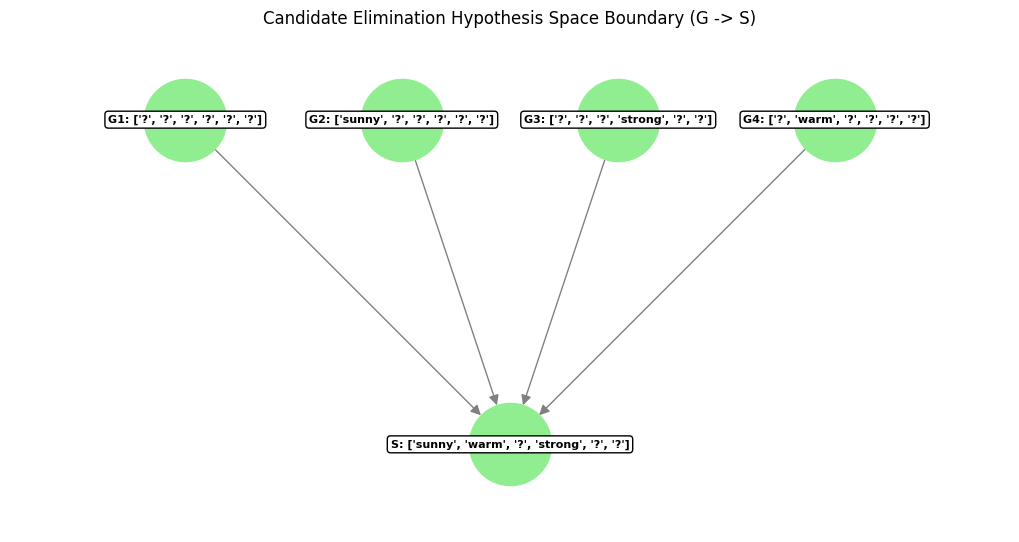

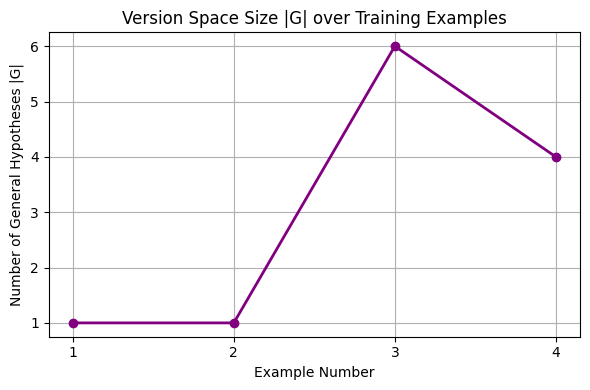

In [2]:
H = nx.DiGraph()

s_label = "S: " + str(S)
H.add_node(s_label)

g_labels = []
for idx, g in enumerate(G):
    g_label = f"G{idx+1}: " + str(g)
    g_labels.append(g_label)
    H.add_node(g_label)
    if covers(g, S):
        H.add_edge(g_label, s_label)

pos = {}
pos[s_label] = (0.5, 0.1)

n_g = len(g_labels)
for idx, g_label in enumerate(g_labels):
    pos[g_label] = (idx / max(1, n_g - 1) if n_g > 1 else 0.5, 0.9)

plt.figure(figsize=(10, 5))
nx.draw(H, pos, with_labels=True, node_color='lightgreen', edge_color='gray',
        node_size=3500, font_size=8, font_weight='bold', arrows=True,
        arrowsize=15, arrowstyle='-|>', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))
plt.title('Candidate Elimination Hypothesis Space Boundary (G -> S)')
plt.margins(0.2)
plt.axis('off')
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(version_sizes) + 1), version_sizes, marker='o', color='purple', linewidth=2)
plt.title('Version Space Size |G| over Training Examples')
plt.xlabel('Example Number')
plt.ylabel('Number of General Hypotheses |G|')
plt.xticks(range(1, len(version_sizes) + 1))
plt.grid(True)
plt.tight_layout()
plt.show()